<a href="https://colab.research.google.com/github/venkatasai-eng/Computer-Vision/blob/main/Exp_30.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Saving man.avif to man.avif


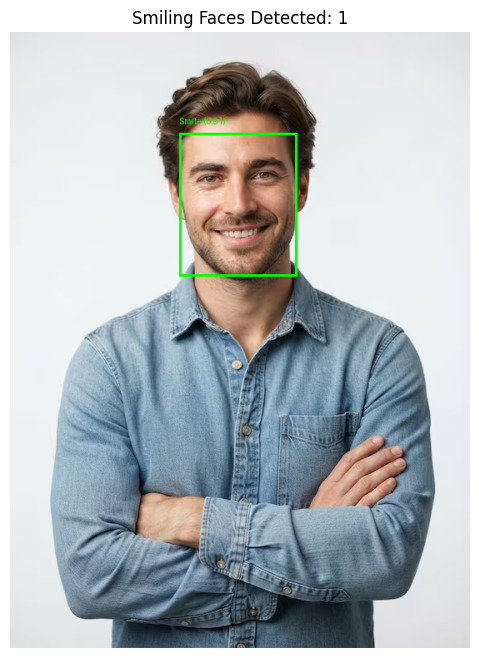

Number of smiling faces: 1


In [6]:
!pip install -q mediapipe pillow pillow-avif-plugin

import mediapipe as mp
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
from google.colab import files
import urllib.request
import pillow_avif

url = "https://storage.googleapis.com/mediapipe-models/face_landmarker/face_landmarker/float16/1/face_landmarker.task"
urllib.request.urlretrieve(url, "face.task")

uploaded = files.upload()
img = Image.open(next(iter(uploaded))).convert("RGB")
image = np.array(img)

options = mp.tasks.vision.FaceLandmarkerOptions(
    base_options=mp.tasks.BaseOptions(model_asset_path="face.task"),
    running_mode=mp.tasks.vision.RunningMode.IMAGE,
    output_face_blendshapes=True,
    num_faces=10
)

draw = ImageDraw.Draw(img)
count = 0

with mp.tasks.vision.FaceLandmarker.create_from_options(options) as detector:
    mp_image = mp.Image(
        image_format=mp.ImageFormat.SRGB,
        data=image
    )
    results = detector.detect(mp_image)

    for i, face in enumerate(results.face_landmarks):
        scores = {
            item.category_name: item.score
            for item in results.face_blendshapes[i]
        }

        left = scores.get("mouthSmileLeft", 0)
        right = scores.get("mouthSmileRight", 0)
        smile_score = (left + right) / 2

        xs = [p.x * img.width for p in face]
        ys = [p.y * img.height for p in face]

        x1, y1 = int(min(xs)), int(min(ys))
        x2, y2 = int(max(xs)), int(max(ys))

        if smile_score > 0.25:
            label = f"Smile ({smile_score:.2f})"
            color = "lime"
            count += 1
        else:
            label = f"No Smile ({smile_score:.2f})"
            color = "red"

        draw.rectangle((x1, y1, x2, y2), outline=color, width=3)
        draw.text((x1, max(0, y1 - 20)), label, fill=color)

plt.figure(figsize=(12, 8))
plt.imshow(img)
plt.title(f"Smiling Faces Detected: {count}")
plt.axis("off")
plt.show()

print("Number of smiling faces:", count)